In [ ]:
import kagglehub
path = kagglehub.dataset_download("taweilo/loan-approval-classification-data")
print(path)

100%|██████████| 751k/751k [00:00<00:00, 1.61MB/s]

Extracting files...
/root/.cache/kagglehub/datasets/taweilo/loan-approval-classification-data/versions/1


In [1]:
#import data
import pandas as pd
df=pd.read_csv('/content/loan_data.csv')
print(df)

       person_age person_gender person_education  person_income  \
0            22.0        female           Master        71948.0   
1            21.0        female      High School        12282.0   
2            25.0        female      High School        12438.0   
3            23.0        female         Bachelor        79753.0   
4            24.0          male           Master        66135.0   
...           ...           ...              ...            ...   
44995        27.0          male        Associate        47971.0   
44996        37.0        female        Associate        65800.0   
44997        33.0          male        Associate        56942.0   
44998        29.0          male         Bachelor        33164.0   
44999        24.0          male      High School        51609.0   

       person_emp_exp person_home_ownership  loan_amnt        loan_intent  \
0                   0                  RENT    35000.0           PERSONAL   
1                   0                   O

In [2]:
#Clean the data
df = pd.get_dummies(df, columns=[
    'person_gender',
    'person_education',
    'person_home_ownership',
    'loan_intent',
    'previous_loan_defaults_on_file'
], drop_first=True)

df = df[df['person_age'] <= 80]

df = df[df['person_emp_exp'] < df['person_age']]



print(df)


       person_age  person_income  person_emp_exp  loan_amnt  loan_int_rate  \
0            22.0        71948.0               0    35000.0          16.02   
1            21.0        12282.0               0     1000.0          11.14   
2            25.0        12438.0               3     5500.0          12.87   
3            23.0        79753.0               0    35000.0          15.23   
4            24.0        66135.0               1    35000.0          14.27   
...           ...            ...             ...        ...            ...   
44995        27.0        47971.0               6    15000.0          15.66   
44996        37.0        65800.0              17     9000.0          14.07   
44997        33.0        56942.0               7     2771.0          10.02   
44998        29.0        33164.0               4    12000.0          13.23   
44999        24.0        51609.0               1     6665.0          17.05   

       loan_percent_income  cb_person_cred_hist_length  credit_

Text(0, 0.5, 'Loan Amount')

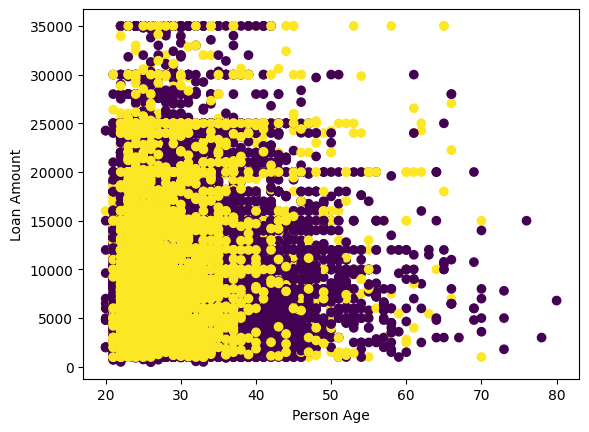

In [3]:
#visualize the data
import matplotlib.pyplot as plt
plt.scatter(df['person_age'], df['loan_amnt'],c=df['loan_status'])
plt.xlabel('Person Age')
plt.ylabel('Loan Amount')

Text(0, 0.5, 'Loan Amount')

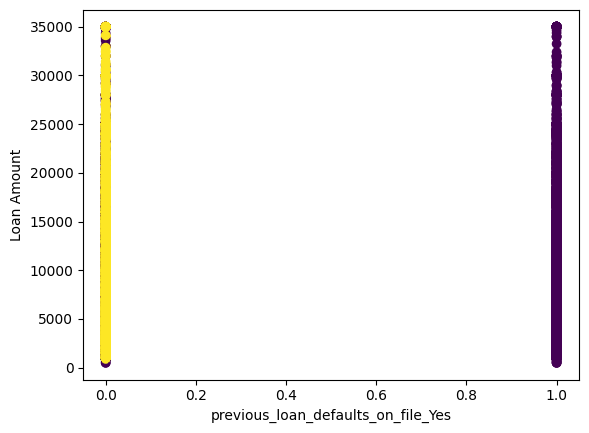

In [4]:
plt.scatter(df['previous_loan_defaults_on_file_Yes'], df['loan_amnt'],c=df['loan_status'])
plt.xlabel('previous_loan_defaults_on_file_Yes')
plt.ylabel('Loan Amount')

In [5]:
#Feed the data to model
x = df.drop(columns=['loan_status'])
y=df['loan_status']



In [6]:
#seperate data for training and testing
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=42)

In [7]:
import numpy as np
print(x_train.shape)
print(x_test.shape)
print(y_train.shape)
print(y_test.shape)

(35992, 22)
(8999, 22)
(35992,)
(8999,)


In [8]:
#reduce variation of data to get better accuracy
from sklearn.preprocessing import StandardScaler
scaler=StandardScaler()
x_train=scaler.fit_transform(x_train)
x_test=scaler.transform(x_test)

In [21]:
#reduced the dimensions of x training data to plot decison region graph
from sklearn.decomposition import PCA
pca=PCA(n_components=2)
x_train_pca=pca.fit_transform(x_train)
x_test_pca=pca.transform(x_test)


In [22]:
#Training the model
from sklearn.linear_model import LogisticRegression
model=LogisticRegression()
model.fit(x_train_pca,y_train)

LogisticRegression()

In [23]:
#Accuracy of model after training
from sklearn.metrics import accuracy_score
y_pred=model.predict(x_test_pca)
accuracy=accuracy_score(y_test,y_pred)
print(accuracy)

0.8417601955772863


Text(0, 0.5, 'Loan Amount')

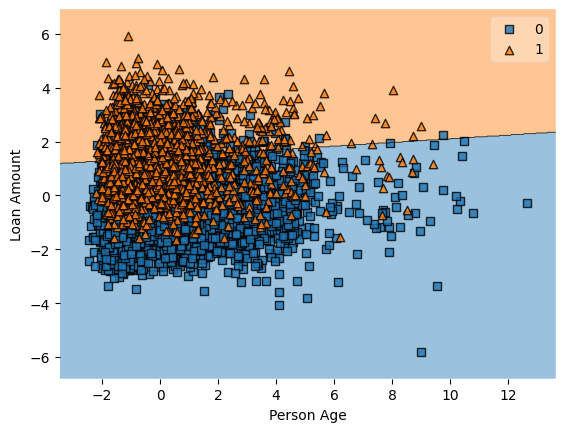

In [24]:
#Deecision region graph
from mlxtend.plotting import plot_decision_regions
plot_decision_regions(x_test_pca,y_test.values.astype(int).ravel(),clf=model)
plt.xlabel('Person Age')
plt.ylabel('Loan Amount')